<h2 style='color:blue' align="center">KNN (K Nearest Neighbors) Classification: Machine Tutorial Using Python Sklearn</h2>

<a id="s1"></a>
# 1️⃣ What is KNN?

### 🧠 The idea in one sentence
> **"Tell me who your neighbours are, and I'll tell you who you are."**

Imagine you move to a new city and want to guess whether a restaurant is good. You ask the **K** people living closest to it. If most of them say *"good"*, you guess *good*. That is exactly KNN.

KNN is a **supervised** learning algorithm: we give it examples **with the correct answers (labels)**, and it uses them to label new, unseen examples.

<p align="center">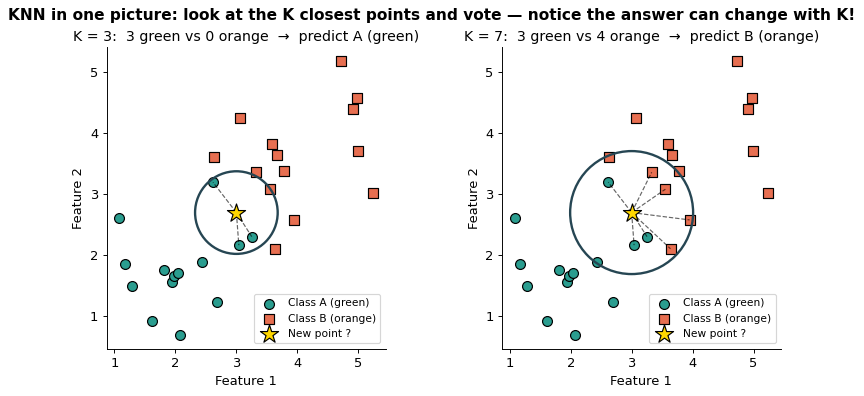<br><em>The gold star is a new point. With K = 3 its neighbours vote green; with K = 7 they vote orange. K matters!</em></p>

### 🧠 The algorithm — only 4 steps
To predict the class of a new point $x_{new}$:

1. **Choose K** — how many neighbours to consult (e.g. 3, 5, 7).
2. **Measure the distance** from $x_{new}$ to *every* point in the training data.
3. **Pick the K closest** points (the "nearest neighbours").
4. **Vote** — the most common class among those K neighbours is the prediction.

📐 Written as a formula, the prediction is the class $c$ that appears most often among the neighbours $N_K(x_{new})$:

$$\hat{y} = \underset{c}{\arg\max} \sum_{i \in N_K(x_{new})} \mathbb{1}(y_i = c)$$

Here $\mathbb{1}(y_i = c)$ is **1** if neighbour $i$ belongs to class $c$, otherwise **0** — so the sum simply *counts votes*.

### 🧠 KNN is a "lazy learner"
Most algorithms learn an equation during training. KNN does **not** — "training" just means **storing** the data. All the work happens at prediction time. That makes training instant but prediction slow on huge datasets.



<a id="s2"></a>
# 2️⃣ Measuring distance — what does "nearest" mean?

"Nearest" needs a way to measure distance. The two most common are:

<p align="center">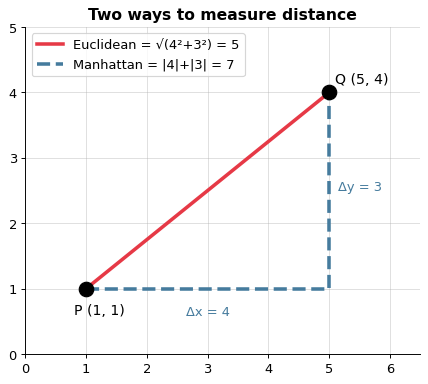</p>

### 📐 Euclidean distance (straight line — the default)
For two points $p = (p_1, \dots, p_n)$ and $q = (q_1, \dots, q_n)$:

$$d_{Euclidean}(p, q) = \sqrt{\sum_{i=1}^{n} (p_i - q_i)^2}$$

*In 2-D this is just Pythagoras' theorem:* $\sqrt{4^2 + 3^2} = \sqrt{25} = 5$.

### 📐 Manhattan distance ("city-block" — walking along streets)
$$d_{Manhattan}(p, q) = \sum_{i=1}^{n} |p_i - q_i|$$

For the picture: $|5-1| + |4-1| = 4 + 3 = 7$.

### 📐 Minkowski distance (the general family)
$$d_{Minkowski}(p, q) = \left(\sum_{i=1}^{n} |p_i - q_i|^{\,p}\right)^{1/p}$$

* $p = 1$ → Manhattan  * $p = 2$ → Euclidean (scikit-learn's default: `metric='minkowski', p=2`)

▶️ Let's check the numbers from the picture with code.

<a id="s3"></a>
# 3️⃣ Worked example — KNN by hand ✏️

Before using any library, let's do KNN with pencil and paper. We have 6 flowers with two measurements and a known species:

| Flower | Petal length (cm) | Petal width (cm) | Species |
|:-:|:-:|:-:|:-:|
| A | 1.4 | 0.2 | setosa |
| B | 1.3 | 0.3 | setosa |
| C | 4.5 | 1.5 | versicolor |
| D | 4.0 | 1.3 | versicolor |
| E | 5.8 | 2.2 | virginica |
| F | 5.1 | 1.9 | virginica |

**New flower:** petal length = **4.8**, petal width = **1.7**. What species is it? Use **K = 3**.

**Step 1 – distances** (Euclidean):

| Flower | Calculation | Distance |
|:-:|:--|:-:|
| A | $\sqrt{(4.8-1.4)^2 + (1.7-0.2)^2} = \sqrt{11.56+2.25}$ | 3.72 |
| B | $\sqrt{(4.8-1.3)^2 + (1.7-0.3)^2} = \sqrt{12.25+1.96}$ | 3.77 |
| C | $\sqrt{(4.8-4.5)^2 + (1.7-1.5)^2} = \sqrt{0.09+0.04}$ | **0.36** |
| D | $\sqrt{(4.8-4.0)^2 + (1.7-1.3)^2} = \sqrt{0.64+0.16}$ | **0.89** |
| E | $\sqrt{(4.8-5.8)^2 + (1.7-2.2)^2} = \sqrt{1.00+0.25}$ | 1.12 |
| F | $\sqrt{(4.8-5.1)^2 + (1.7-1.9)^2} = \sqrt{0.09+0.04}$ | **0.36** |

**Step 2 – the 3 nearest:** C (0.36), F (0.36), D (0.89)

**Step 3 – vote:** versicolor 🟦🟦 vs virginica 🟥 → **Prediction: versicolor** ✅

▶️ Now let the computer verify our hand calculation:

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

%matplotlib inline

In [ ]:
# Load the Iris Dataset
iris = load_iris()

print("Feature names:")
print(iris.feature_names)

print("\nTarget names:")
print(iris.target_names)

print("\nDataset shape:")
print(iris.data.shape)

Feature names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target names:
['setosa' 'versicolor' 'virginica']

Dataset shape:
(150, 4)


[![iris-petal-sepal.png](https://i.postimg.cc/5ts6F3BK/iris-petal-sepal.png)](https://postimg.cc/Z9yTG6D6)

# view feature_names

In [ ]:
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

# view the target_names

In [ ]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [4]:
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


# Add iris.target to df['target']

In [5]:
df['target'] = iris.target

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [ ]:
df[df.target==1].head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
50,7.0,3.2,4.7,1.4,1
51,6.4,3.2,4.5,1.5,1
52,6.9,3.1,4.9,1.5,1
53,5.5,2.3,4.0,1.3,1
54,6.5,2.8,4.6,1.5,1


In [ ]:
df[df.target==2].head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
100,6.3,3.3,6.0,2.5,2
101,5.8,2.7,5.1,1.9,2
102,7.1,3.0,5.9,2.1,2
103,6.3,2.9,5.6,1.8,2
104,6.5,3.0,5.8,2.2,2


In [ ]:
df['flower_name'] =df.target.apply(lambda x: iris.target_names[x])
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,flower_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [ ]:
df[45:55]

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,flower_name
45,4.8,3.0,1.4,0.3,0,setosa
46,5.1,3.8,1.6,0.2,0,setosa
47,4.6,3.2,1.4,0.2,0,setosa
48,5.3,3.7,1.5,0.2,0,setosa
49,5.0,3.3,1.4,0.2,0,setosa
50,7.0,3.2,4.7,1.4,1,versicolor
51,6.4,3.2,4.5,1.5,1,versicolor
52,6.9,3.1,4.9,1.5,1,versicolor
53,5.5,2.3,4.0,1.3,1,versicolor
54,6.5,2.8,4.6,1.5,1,versicolor


In [ ]:
df0 = df[:50]
df1 = df[50:100]
df2 = df[100:]

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline

**Sepal length vs Sepal Width (Setosa vs Versicolor)**

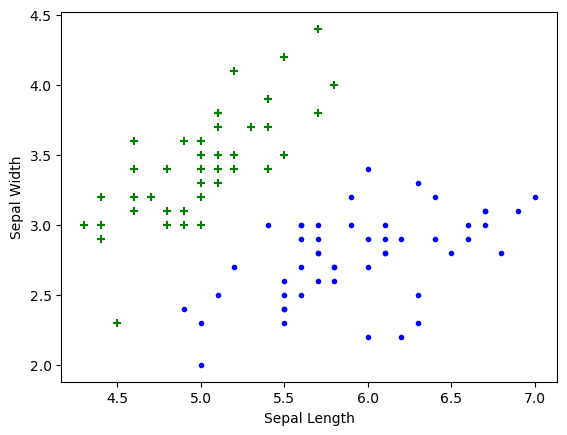

In [ ]:
plt.xlabel('Sepal Length')
plt.ylabel('Sepal Width')
plt.scatter(df0['sepal length (cm)'], df0['sepal width (cm)'],color="green",marker='+')
plt.scatter(df1['sepal length (cm)'], df1['sepal width (cm)'],color="blue",marker='.')

**Petal length vs Pepal Width (Setosa vs Versicolor)**

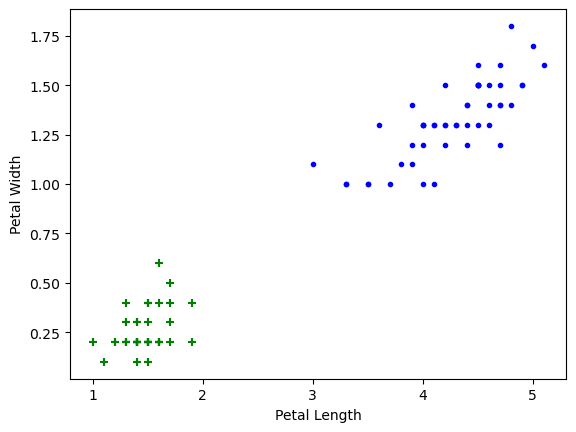

In [ ]:
plt.xlabel('Petal Length')
plt.ylabel('Petal Width')
plt.scatter(df0['petal length (cm)'], df0['petal width (cm)'],color="green",marker='+')
plt.scatter(df1['petal length (cm)'], df1['petal width (cm)'],color="blue",marker='.')

**Train test split**

In [ ]:
from sklearn.model_selection import train_test_split

# remove ['target','flower_name'] in df and prepare the X and Y
###### X = df.drop(['target','flower_name'], axis='columns')
###### y = df.target

In [6]:
X = df.drop(
    columns=['target', 'flower_name'],
    errors='ignore'
)

y = df['target']

print("X shape:", X.shape)
print("Y shape:", y.shape)

X shape: (150, 4)
Y shape: (150,)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [8]:
len(X_train)

120

In [9]:
len(X_test)

30

**Create KNN (K Neighrest Neighbour Classifier)**

In [10]:
knn = KNeighborsClassifier(n_neighbors=10)

knn.fit(X_train, y_train)


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",10
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [11]:
knn.score(X_test, y_test)

0.9666666666666667

In [12]:
knn.score(X_test, y_test)

0.9666666666666667

In [13]:
print(knn.predict([[4.8,3.0,1.5,0.3]]))

[0]


c:\Users\HP\image_proc_lab\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


**Plot Confusion Matrix**

In [ ]:
from sklearn.metrics import confusion_matrix
y_pred = knn.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
cm

array([[11,  0,  0],
       [ 0, 12,  1],
       [ 0,  0,  6]])

Text(58.222222222222214, 0.5, 'Truth')

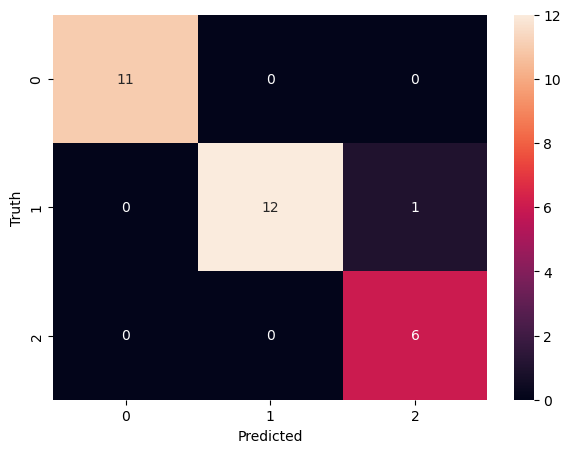

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sn
plt.figure(figsize=(7,5))
sn.heatmap(cm, annot=True)
plt.xlabel('Predicted')
plt.ylabel('Truth')

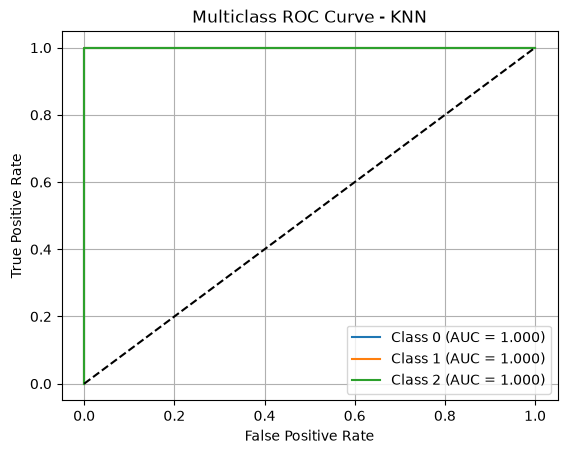

KNN Accuracy: 0.9666666666666667
Macro AUC: 1.0


In [14]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

# Train KNN
knn = KNeighborsClassifier(n_neighbors=10)
knn.fit(X_train, y_train)

# Predict probabilities
y_prob = knn.predict_proba(X_test)

# Convert actual labels to binary format
y_test_bin = label_binarize(y_test, classes=knn.classes_)

# Plot ROC curve for each class
for i, name in enumerate(knn.classes_):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    plt.plot(fpr, tpr, label=f'Class {name} (AUC = {auc(fpr, tpr):.3f})')

# Random classifier line
plt.plot([0, 1], [0, 1], 'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass ROC Curve - KNN')
plt.legend()
plt.grid()
plt.show()

# Overall macro AUC
print("KNN Accuracy:", knn.score(X_test, y_test))
print("Macro AUC:", round(
    roc_auc_score(y_test, y_prob, multi_class='ovr', average='macro'), 3
))


**Print classification report for precesion, recall and f1-score for each classes**

In [18]:
y_pred = knn.predict(X_test)

In [19]:
from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        11
           1       1.00      0.92      0.96        13
           2       0.86      1.00      0.92         6

    accuracy                           0.97        30
   macro avg       0.95      0.97      0.96        30
weighted avg       0.97      0.97      0.97        30



In [20]:
y_pred = knn.predict(X_test)

In [21]:
from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        11
  versicolor       1.00      0.92      0.96        13
   virginica       0.86      1.00      0.92         6

    accuracy                           0.97        30
   macro avg       0.95      0.97      0.96        30
weighted avg       0.97      0.97      0.97        30



In [22]:
from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        11
           1       1.00      0.92      0.96        13
           2       0.86      1.00      0.92         6

    accuracy                           0.97        30
   macro avg       0.95      0.97      0.96        30
weighted avg       0.97      0.97      0.97        30



Bulding KNN from Scrath

# Step 1: Load Dataset


In [28]:
import numpy as np
from collections import Counter

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

iris = load_iris()

X = iris.data[:, :2]
y = iris.target
target_names = iris.target_names

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

In [24]:
# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# euclidean distance

In [25]:
# Euclidean distance
import numpy as np

def euclidean_distance(point1, point2):
    return np.sqrt(np.sum((point1 - point2) ** 2))

# Example
point1 = np.array([1, 2])
point2 = np.array([4, 6])

distance = euclidean_distance(point1, point2)
print("Euclidean Distance:", distance)

Euclidean Distance: 5.0


## Pseudocode: K-Nearest Neighbors (KNN) Prediction

**Algorithm: KNN_Predict**

**Input:**  
- Training data `X_train`
- Training labels `y_train`
- Test data `X_test`
- Number of neighbors `k`

**Output:**  
- Predicted labels `predictions`

### Pseudocode

```text
BEGIN

    Initialize predictions as an empty list

    FOR each test_point in X_test DO

        Initialize distances as an empty list

        FOR each training_point in X_train DO
            distance ← Euclidean_Distance(test_point, training_point)
            Add distance to distances
        END FOR

        nearest_indices ← indices of k smallest values in distances

        nearest_labels ← labels of training points
                          corresponding to nearest_indices

        predicted_label ← most frequent label in nearest_labels

        Add predicted_label to predictions

    END FOR

    RETURN predictions

END


In [29]:
def euclidean_distance(point1, point2):
    return np.sqrt(np.sum((point1 - point2) ** 2))


def knn_predict(X_train, y_train, X_test, k=5):
    predictions = []

    X_train = np.asarray(X_train)
    y_train = np.asarray(y_train)
    X_test = np.asarray(X_test)

    for test_point in X_test:
        distances = [
            euclidean_distance(test_point, train_point)
            for train_point in X_train
        ]

        nearest_indices = np.argsort(distances)[:k]
        nearest_labels = y_train[nearest_indices]

        predicted_label = Counter(nearest_labels).most_common(1)[0][0]
        predictions.append(predicted_label)

    return np.array(predictions)

In [30]:
# -------------------------
# Step 3: Train & Predict
# -------------------------
k = 5
y_pred = knn_predict(X_train, y_train, X_test, k=k)

# -------------------------
# Step 4: Evaluation
# -------------------------
print(f"Accuracy (k={k}):", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=target_names))


Accuracy (k=5): 0.8

Classification Report:
               precision    recall  f1-score   support

      setosa       0.94      1.00      0.97        15
  versicolor       0.73      0.73      0.73        15
   virginica       0.71      0.67      0.69        15

    accuracy                           0.80        45
   macro avg       0.80      0.80      0.80        45
weighted avg       0.80      0.80      0.80        45



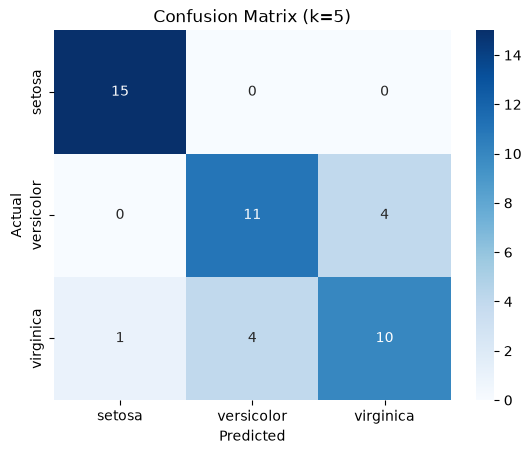

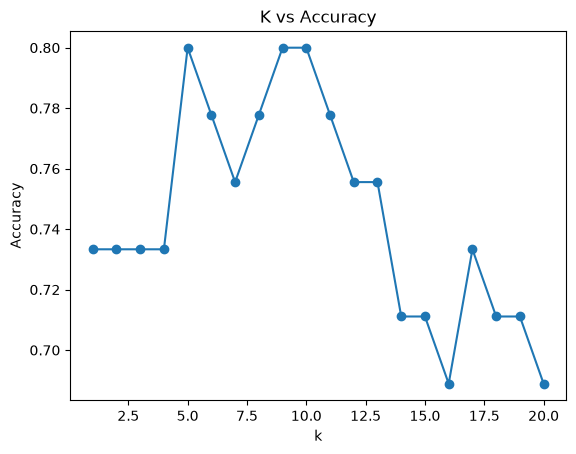

In [31]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=target_names, yticklabels=target_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix (k={k})")
plt.show()





# -------------------------
# Step 6: Accuracy vs k curve
# -------------------------
k_values = range(1, 21)
acc_scores = []
for k in k_values:
    y_pred_k = knn_predict(X_train, y_train, X_test, k=k)
    acc_scores.append(accuracy_score(y_test, y_pred_k))

plt.plot(k_values, acc_scores, marker="o")
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.title("K vs Accuracy")
plt.show()


<a id="s9"></a>
# 9️⃣ Choosing the best K

<p align="center">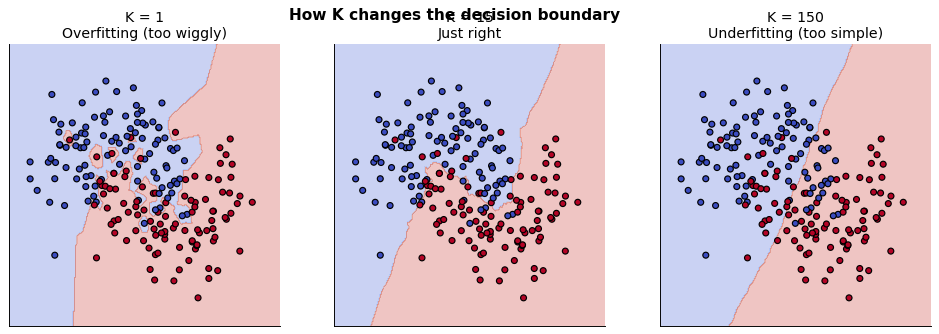</p>

| K | Behaviour | Problem |
|---|---|---|
| Very small (K = 1) | follows every single point, even noise | **Overfitting** – high variance |
| Very large (K ≈ n) | always predicts the majority class | **Underfitting** – high bias |
| In between | smooth but flexible boundary | ✅ |

**Rules of thumb:** start with $K \approx \sqrt{n_{train}}$ (here $\sqrt{120} \approx 11$), prefer odd K, and then **test several values**.

▶️ Let's try K = 1 … 30 and plot the test accuracy:

<a id="s15"></a>
# 1️⃣5️⃣ ✍️ Practice exercise — handwritten digits

Now apply everything to a new dataset on your own. `load_digits()` contains **1 797 images** of handwritten digits 0–9. Each image is **8 × 8 pixels = 64 features** (pixel brightness 0–16).

### Your tasks
1. Load the digits dataset and look at some images.
2. Split into train/test sets (`test_size=0.2`, `random_state=10`).
3. Train a KNN classifier. Try different values of K 
4. Plot the **confusion matrix**. Which digits are confused most often?
5. Print the **classification report**. Which digit has the lowest F1-score?

▶️ Here's a starter to visualise the data:

Data shape: (1797, 64)


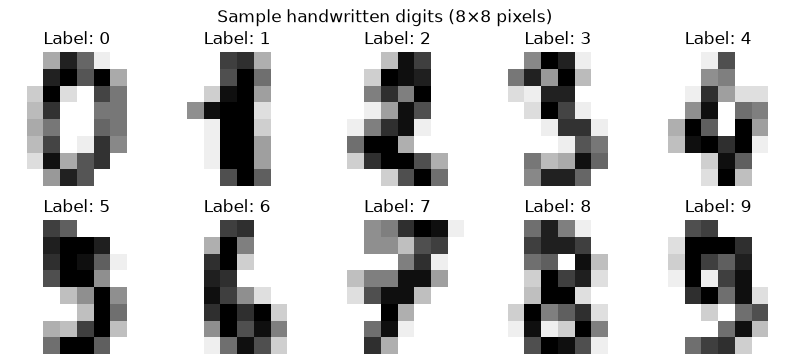

In [32]:
from sklearn.datasets import load_digits
digits = load_digits()
import matplotlib.pyplot as plt
digits = load_digits()
print("Data shape:", digits.data.shape)   # (samples, 64 pixels)

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, image, label in zip(axes.ravel(), digits.images, digits.target):
    ax.imshow(image, cmap='gray_r'); ax.set_title(f"Label: {label}"); ax.axis('off')
plt.suptitle("Sample handwritten digits (8×8 pixels)"); plt.show()